<a href="https://colab.research.google.com/github/Novita-data/Exit_exam/blob/main/Exit_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [63]:
filepath='/content/drive/MyDrive/dsa b11/G1.csv'
df=pd.read_csv(filepath)

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Splitting
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder

# Classification Models & Metrics
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Model Saving
import joblib
import pickle

In [13]:
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

In [5]:
df.dtypes

,0
Response_ID,int64
Timestamp,object
Age,object
Gender,object
Occupation_Status,object
Country_Region,object
Monthly_Income_Range,object
Shop_Most_Where,object
Online_Shopping_Frequency,object
Preferred_Platform,object


In [6]:
df.describe()

,Response_ID,Review_Influence_Score,Social_Ads_Influence_Score,Price_Comparison_Frequency,Discount_Importance_Score,Likely_To_Buy_After_Ad_Score,Impulse_Purchase_Frequency,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency
count,500.000000,485.000000,479.000000,474.000000,477.000000,475.000000,484.000000,457.000000,450.000000,448.000000
mean,250.500000,3.053608,3.079332,4.139241,3.821803,3.016842,2.590909,7.126915,6.160000,2.187500
std,144.481833,1.128707,1.228144,0.943219,0.989284,1.109857,1.162741,1.592636,1.918425,0.902705
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000
25%,125.750000,2.000000,2.000000,4.000000,3.000000,2.000000,2.000000,6.000000,5.000000,1.000000
50%,250.500000,3.000000,3.000000,4.000000,4.000000,3.000000,2.000000,7.000000,6.000000,2.000000
75%,375.250000,4.000000,4.000000,5.000000,5.000000,4.000000,3.000000,8.000000,7.000000,3.000000
max,500.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,10.000000,10.000000,4.000000


In [7]:
df.shape

(500, 30)

In [9]:
df.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,22
Gender,16
Occupation_Status,21
Country_Region,20
Monthly_Income_Range,21
Shop_Most_Where,16
Online_Shopping_Frequency,19
Preferred_Platform,14


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
# Separate Numerical and Categorical Columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


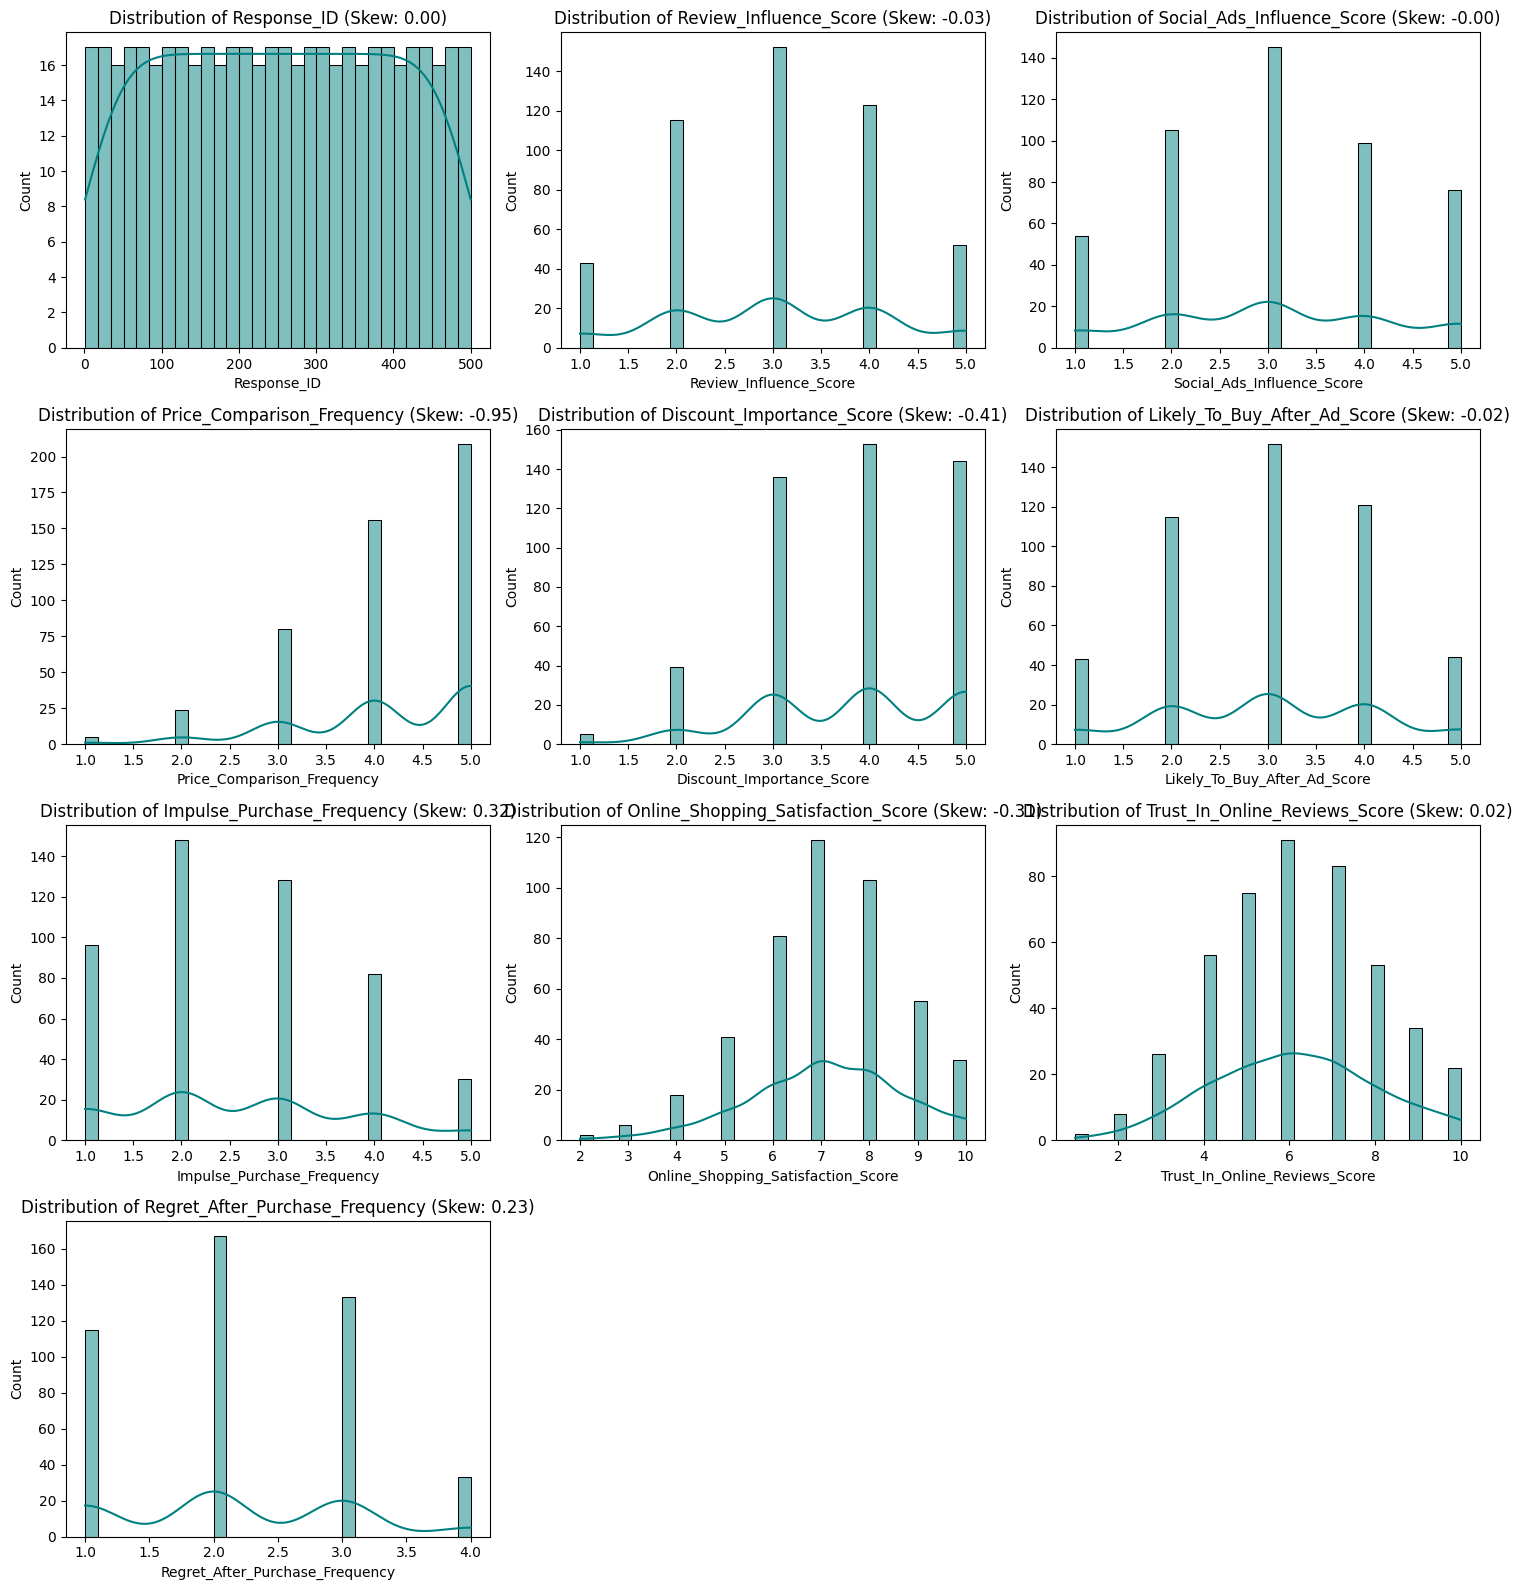

In [12]:
plt.figure(figsize=(15, 4 * ((len(num_cols) + 2) // 3)))
for i, col in enumerate(num_cols, 1):
    plt.subplot((len(num_cols) + 2) // 3, 3, i)
    sns.histplot(df[col], kde=True, bins=30, color='teal')
    plt.title(f'Distribution of {col} (Skew: {df[col].skew():.2f})')
plt.tight_layout()
plt.show()

In [24]:
#df = df.drop(columns=['Resonse_ID'])

In [28]:
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

In [17]:
#distribution of target variable
df['Best_Shopping_Mode'].value_counts()

,count
Best_Shopping_Mode,
Online,218
Offline,118
Equal / both,113


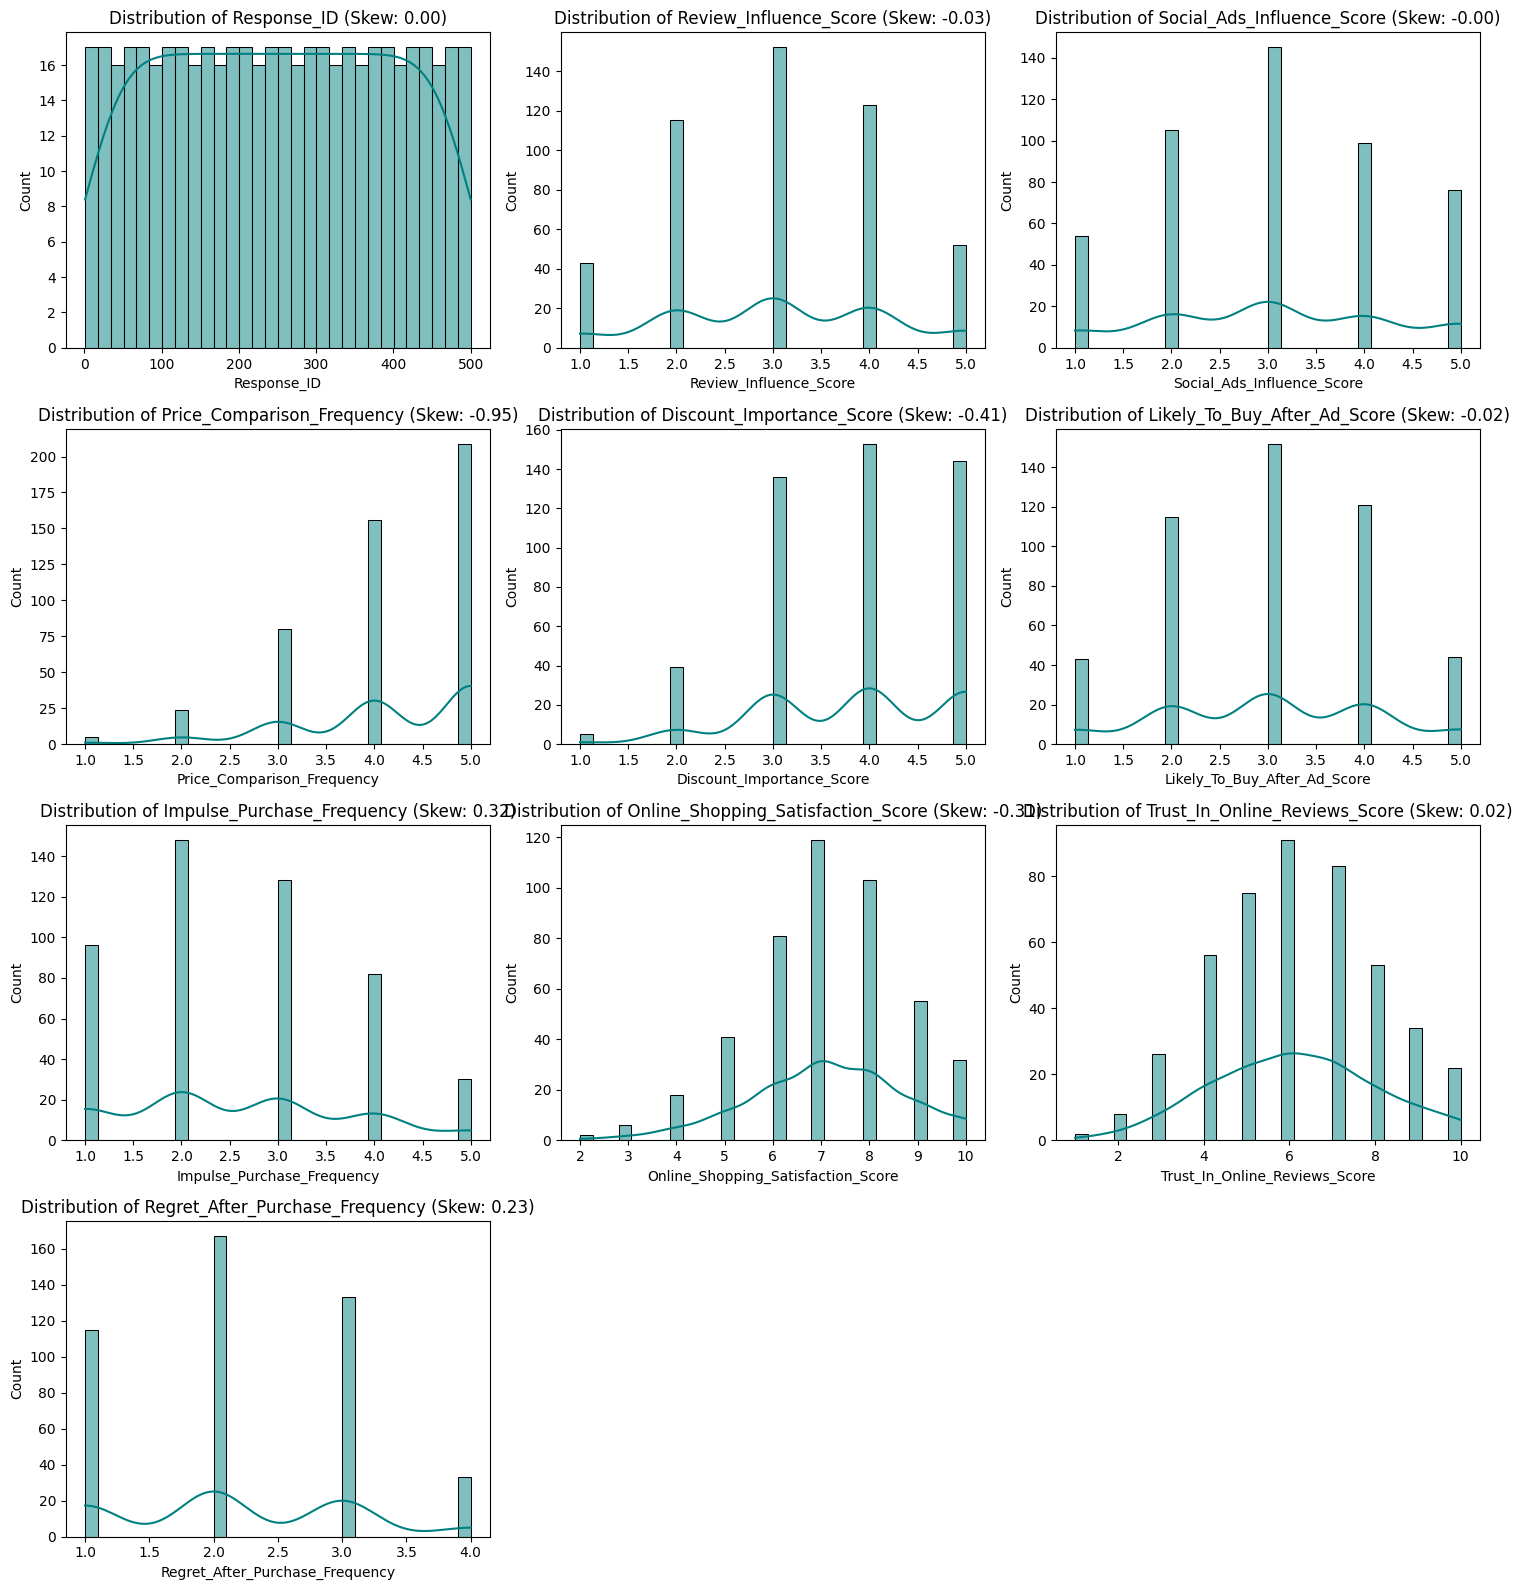

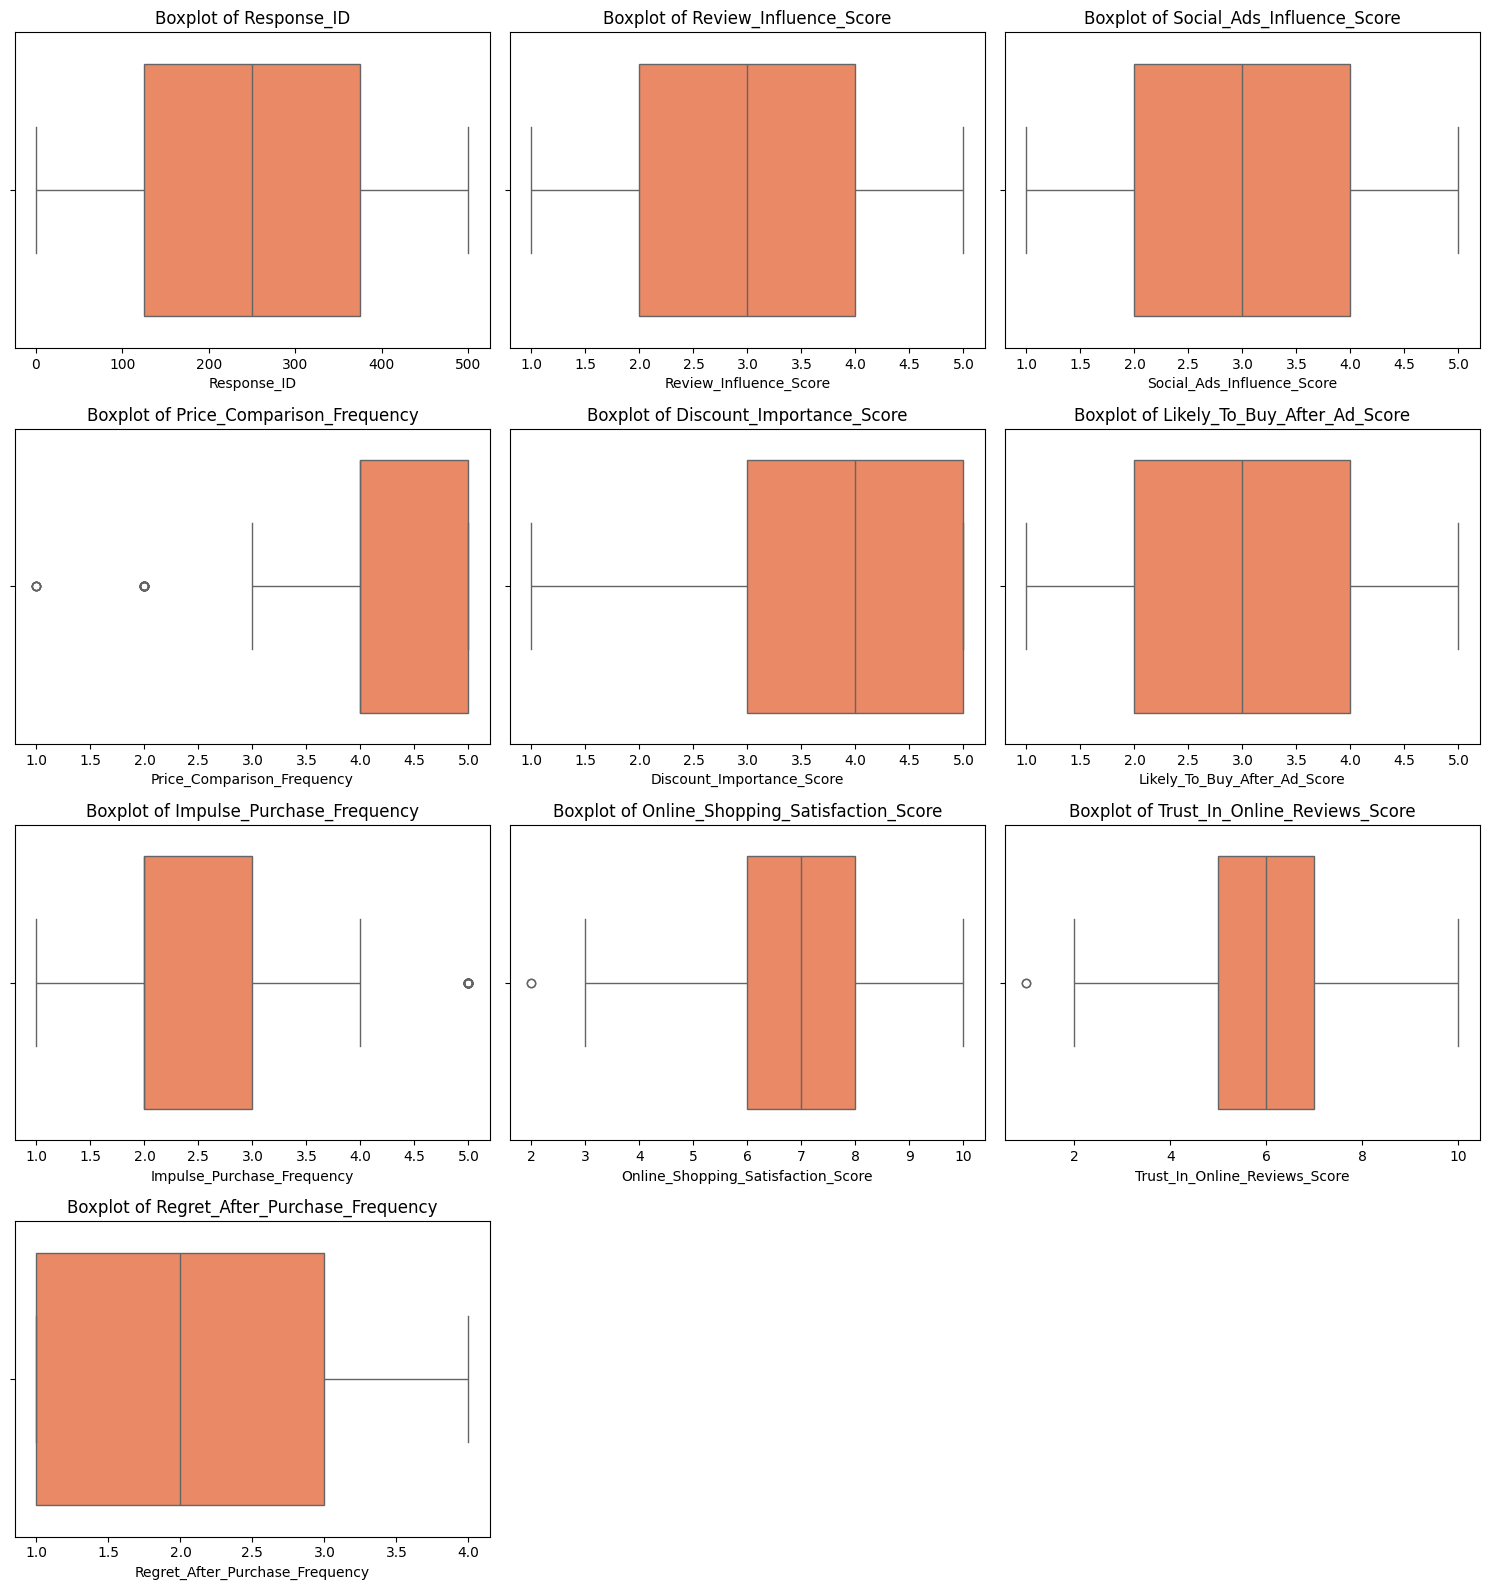

In [30]:
# Separate Numerical and Categorical Columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Remove target column from num_cols if needed
target_col = 'Best_Shopping_Mode' # <-- REPLACE WITH YOUR TARGET COLUMN NAME
if target_col in num_cols:
    num_cols.remove(target_col)

# 1. Distribution Plots (KDE + Histogram) for all Numerical Columns
plt.figure(figsize=(15, 4 * ((len(num_cols) + 2) // 3)))
for i, col in enumerate(num_cols, 1):
    plt.subplot((len(num_cols) + 2) // 3, 3, i)
    sns.histplot(df[col], kde=True, bins=30, color='teal')
    plt.title(f'Distribution of {col} (Skew: {df[col].skew():.2f})')
plt.tight_layout()
plt.show()

# 2. Boxplots for Outlier Detection across all Numerical Columns
plt.figure(figsize=(15, 4 * ((len(num_cols) + 2) // 3)))
for i, col in enumerate(num_cols, 1):
    plt.subplot((len(num_cols) + 2) // 3, 3, i)
    sns.boxplot(x=df[col], color='coral')
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

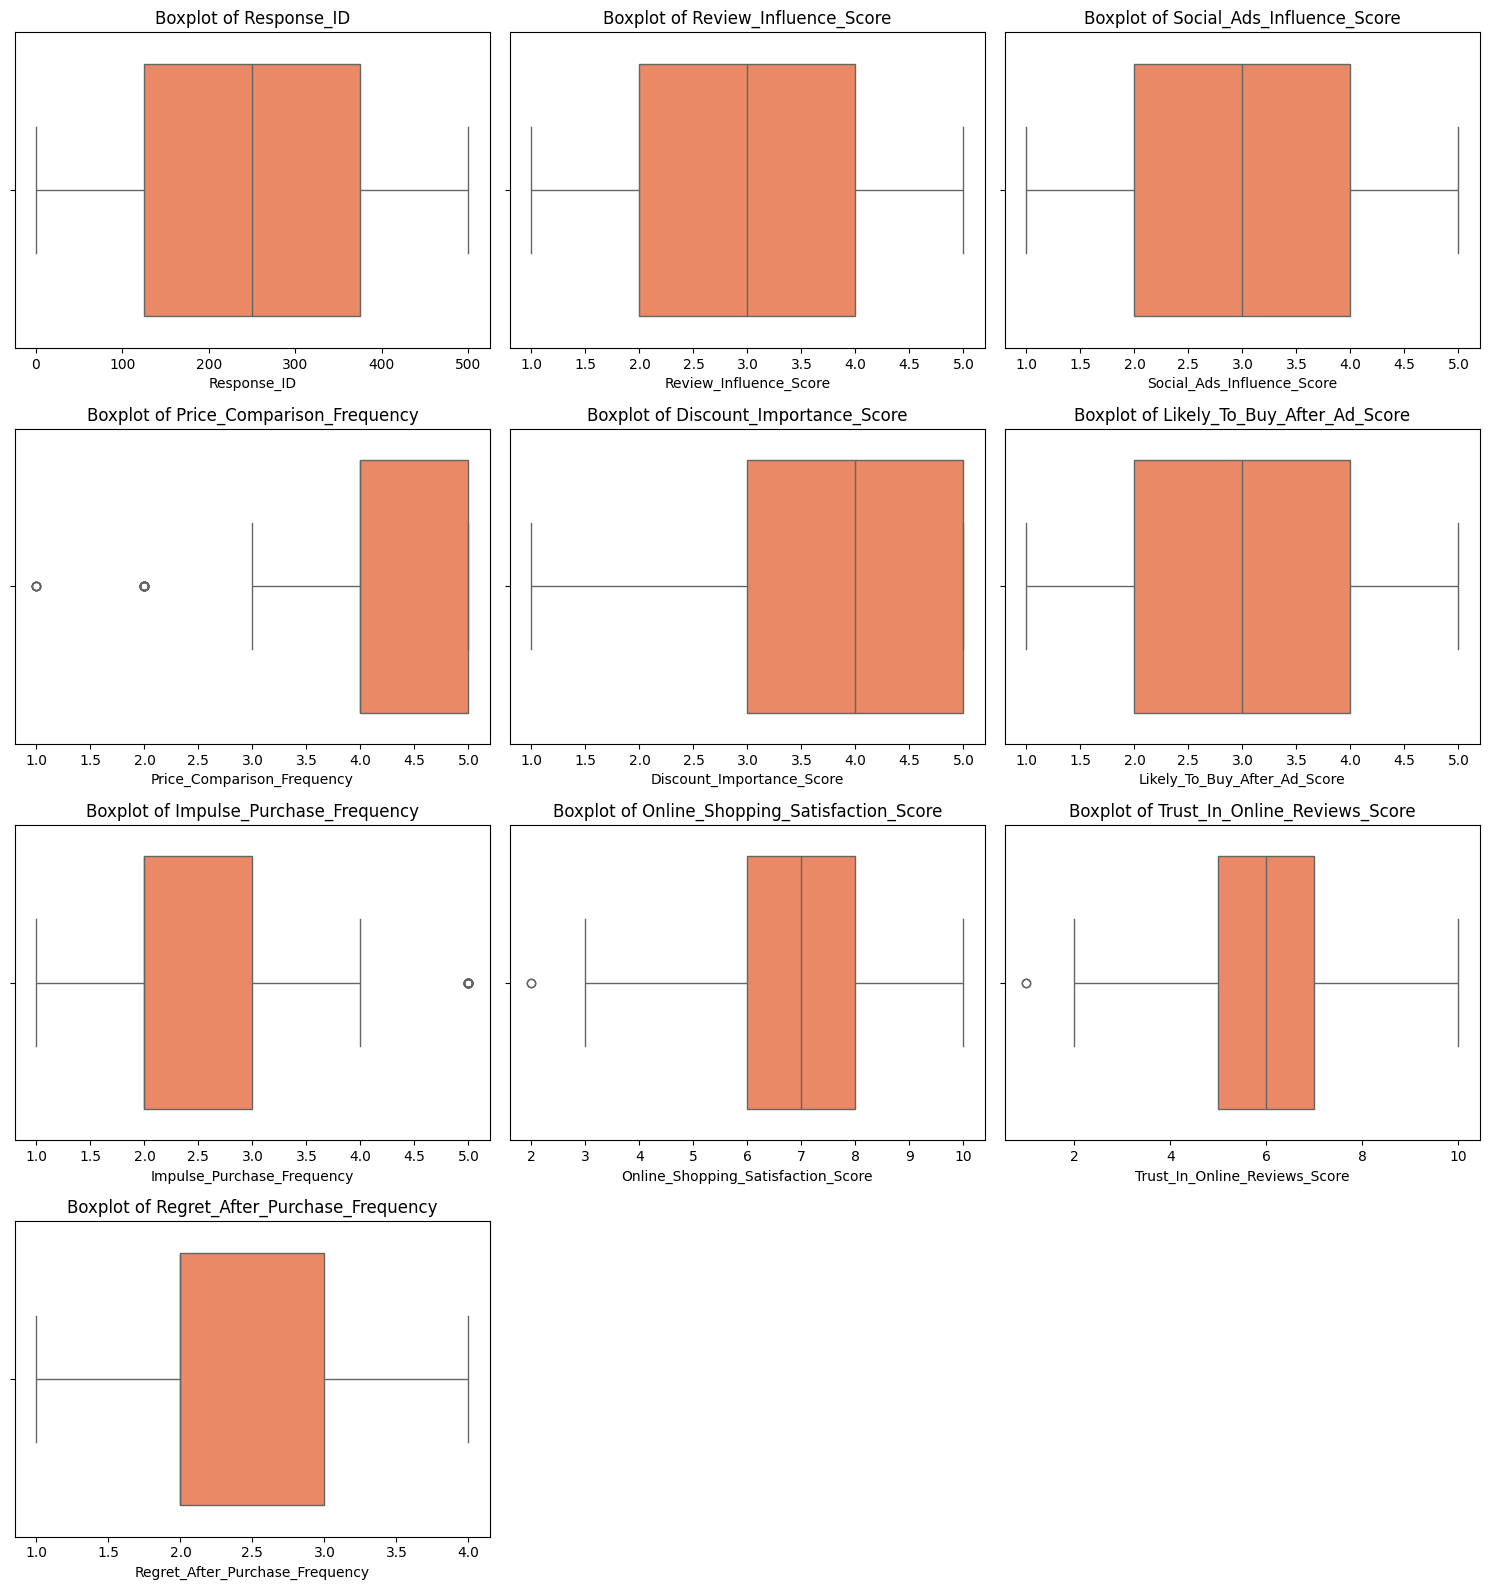

In [44]:
# #2. Boxplots for Outlier Detection across all Numerical Columns
# plt.figure(figsize=(15, 4 * ((len(num_cols) + 2) // 3)))
# for i, col in enumerate(num_cols, 1):
#     plt.subplot((len(num_cols) + 2) // 3, 3, i)
#     sns.boxplot(x=df[col], color='coral')
#     plt.title(f'Boxplot of {col}')
# plt.tight_layout()
# plt.show()

In [35]:
X = df.drop(columns=[target_col])
y = df[target_col]




In [33]:
df.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,22
Gender,16
Occupation_Status,21
Country_Region,20
Monthly_Income_Range,21
Shop_Most_Where,16
Online_Shopping_Frequency,19
Preferred_Platform,14


the dataset is not balanced.monthly income is the large scale value that dominates.

In [ ]:
the

Analytical session

Task 2

In [41]:
for col in num_cols:
    val = df[col].median()
    df[col].fillna(val, inplace=True)

for col in cat_cols:
    if col in df.columns:
        val = df[col].mode()[0]
        df[col].fillna(val, inplace=True)

/tmp/ipykernel_1021/3860736733.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(val, inplace=True)
/tmp/ipykernel_1021/3860736733.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.metho

In [42]:
# 1. Drop rows where target column is missing before splitting
df_clean = df.dropna(subset=[target_col])

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

# 2. Perform Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Impute missing values using values learned from X_train to prevent leakage
for col in num_cols:
    if col in X_train.columns:
        val = X_train[col].median()
        X_train[col] = X_train[col].fillna(val)
        X_test[col] = X_test[col].fillna(val)

for col in cat_cols:
    if col in X_train.columns:
        val = X_train[col].mode()[0]
        X_train[col] = X_train[col].fillna(val)
        X_test[col] = X_test[col].fillna(val)

print("X_train shape:", X_train.shape, "X_test shape:", X_test.shape)
print("Missing values in X_train after imputation:", X_train.isnull().sum().sum())

X_train shape: (400, 29) X_test shape: (100, 29)
Missing values in X_train after imputation: 0


In [43]:
X_train.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,0
Gender,0
Occupation_Status,0
Country_Region,0
Monthly_Income_Range,0
Shop_Most_Where,0
Online_Shopping_Frequency,0
Preferred_Platform,0


No the dataset is not balanced.

In [ ]:
#No duplicate values present. checked initially

In [45]:
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [51]:
# Filter cat_cols to only include columns present in X_train
valid_cat_cols = [col for col in cat_cols if col in X_train.columns]
X_train[valid_cat_cols].value_counts()

,,,,,,,,,,,,,,,,,,,count
Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,Primary_Device,Top_Spending_Category,Follows_Brands_On_Social,Makes_Shopping_List,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Reason_Prefer_Online,Reason_Prefer_InStore,
01/07/2026 05:06:37,19,Male,Student,United Kingdom,"Under $1,000",Online only,Occasionally,Brand websites,Laptop,Clothing,No,Sometimes,Never,Under $50,Digital wallet,"No, never",Convenience,No delivery wait,1
01/07/2026 10:28:05,21,Female,Student,United Kingdom,"Under $1,000",Equal mix,Often,Physical stores,Laptop,Electronics,Yes,Often,Sometimes,Under $50,Cash,"No, never",Better prices,Try product before buying,1
01/07/2026 15:45:54,21,Prefer not to say,Unemployed,Slovakia,"Under $1,000",Online only,Often,Global marketplace (Amazon etc.),Smartphone,Clothing,No,Sometimes,Sometimes,$50-150,Debit Card,"No, never",Convenience,Try product before buying,1
01/07/2026 21:44:22,23,Prefer not to say,Self-employed,Egypt,"Under $1,000",Equal mix,Occasionally,Physical stores,Laptop,Clothing,No,Sometimes,Sometimes,$50-150,Digital wallet,"No, never",More variety,Not applicable,1
01/08/2026 03:14:41,20,Female,Student,Pakistan,"$1,000-3,000",In-store only,Occasionally,Global marketplace (Amazon etc.),Smartphone,Electronics,No,Often,Never,$50-150,Digital wallet,"No, never",Convenience,Not applicable,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31/07/2026 03:45:50,18,Female,Employed part-time,Indonesia,"Under $1,000",Online only,Occasionally,Physical stores,Smartphone,Groceries,No,Sometimes,Never,$50-150,Debit Card,"No, never",Convenience,No delivery wait,1
31/07/2026 06:08:14,25,Male,Employed part-time,Vietnam,"Under $1,000",Equal mix,Occasionally,Brand websites,Smartphone,Groceries,Yes,Never,Never,$50-150,Debit Card,"No, never",More variety,Not applicable,1
31/07/2026 12:03:55,24,Female,Student,Philippines,"Under $1,000",Online only,Rarely,Brand websites,Smartphone,Clothing,No,Often,Never,$50-150,Digital wallet,"No, never",Convenience,Trust,1


In [58]:
new_X_train = X_train.drop(columns=['Timestamp'], errors='ignore')
new_X_test = X_test.drop(columns=['Timestamp'], errors='ignore')

In [59]:
# Remove 'Timestamp' from our categorical features to match our dropped column
final_cat_cols = [col for col in valid_cat_cols if col != 'Timestamp']

# Perform one-hot encoding safely
new_X_train = pd.get_dummies(new_X_train, columns=final_cat_cols, drop_first=True, dtype=int)
new_X_test = pd.get_dummies(new_X_test, columns=final_cat_cols, drop_first=True, dtype=int)

In [61]:
feature_columns = X_train.columns.tolist()
print("Final Features:", feature_columns)

Final Features: ['Response_ID', 'Age', 'Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Follows_Brands_On_Social', 'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List', 'Impulse_Purchase_Frequency', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency', 'Reason_Prefer_Online', 'Reason_Prefer_InStore']


In [62]:
scaler = StandardScaler()
new_X_train[num_cols] = scaler.fit_transform(new_X_train[num_cols])
new_X_test[num_cols] = scaler.transform(new_X_test[num_cols])

1)Handling missing values was the most important. Around 10 numerical columns with different distributions were there. So, I chose median, to avoid any effect of extreme values. But here extreme high irreelevant values are absent. Encoding categorical values to numerical, so machine understands the model, also takes the important decision.

2) Improper missing value handling,
 may give wrong insights about the problem statement.
 will be affected while spliting the datset.

Task 3   EDA

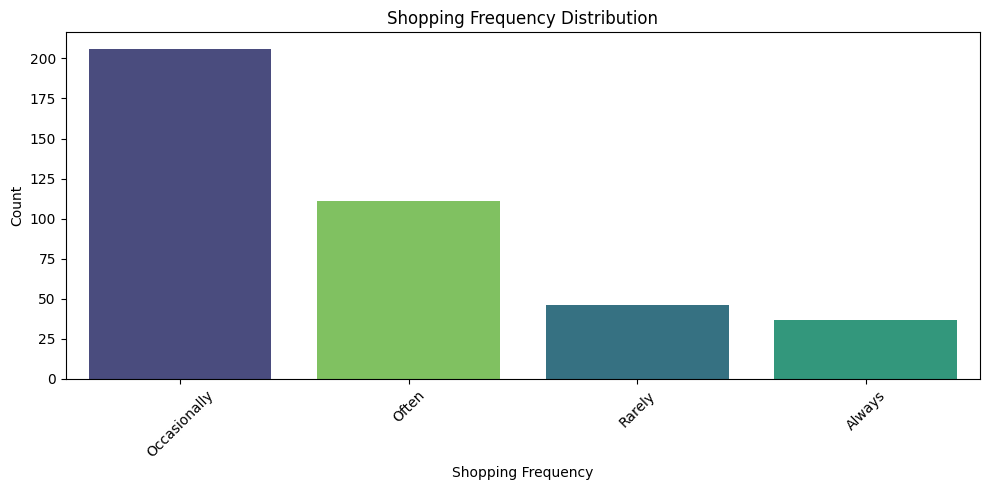

In [75]:
plt.figure(figsize=(10, 5))

# Map x to hue and set legend=False to resolve the Seaborn deprecation warning
sns.countplot(
    data=X_train,
    x='Online_Shopping_Frequency',
    hue='Online_Shopping_Frequency',
    order=X_train['Online_Shopping_Frequency'].value_counts().index,
    palette='viridis',
    legend=False
)

plt.title("Shopping Frequency Distribution")
plt.xlabel("Shopping Frequency")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

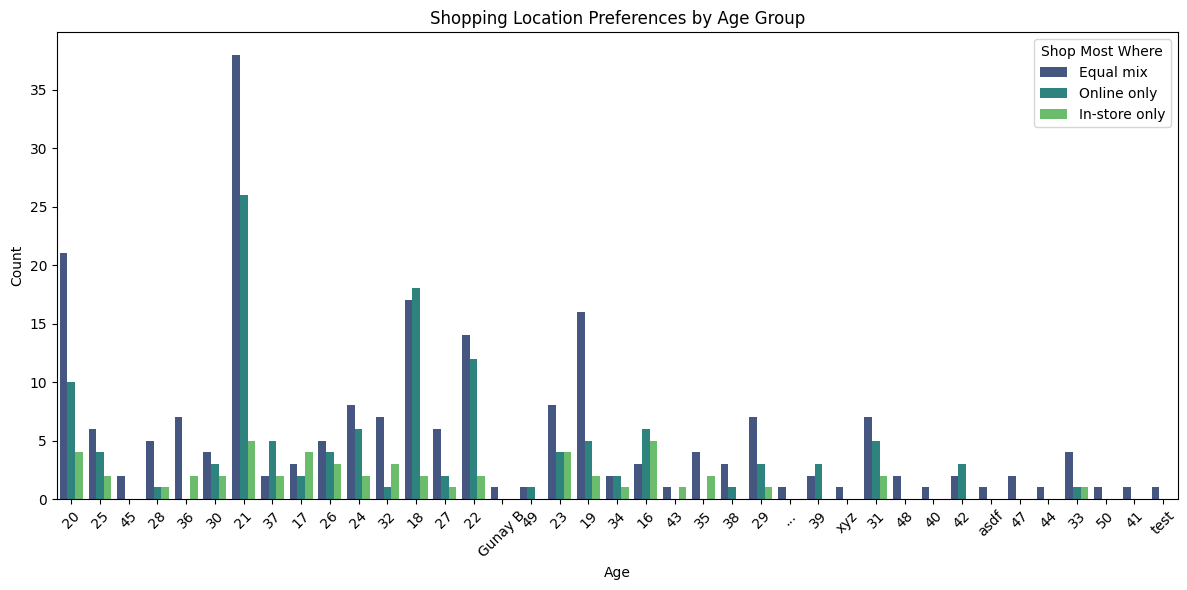

In [73]:
# Calculate the distribution of where people shop most by age group using the unencoded X_train
plt.figure(figsize=(12, 6))
sns.countplot(data=X_train, x='Age', hue='Shop_Most_Where', palette='viridis')

plt.title("Shopping Location Preferences by Age Group")
plt.xlabel("Age")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Shop Most Where")
plt.tight_layout()
plt.show()

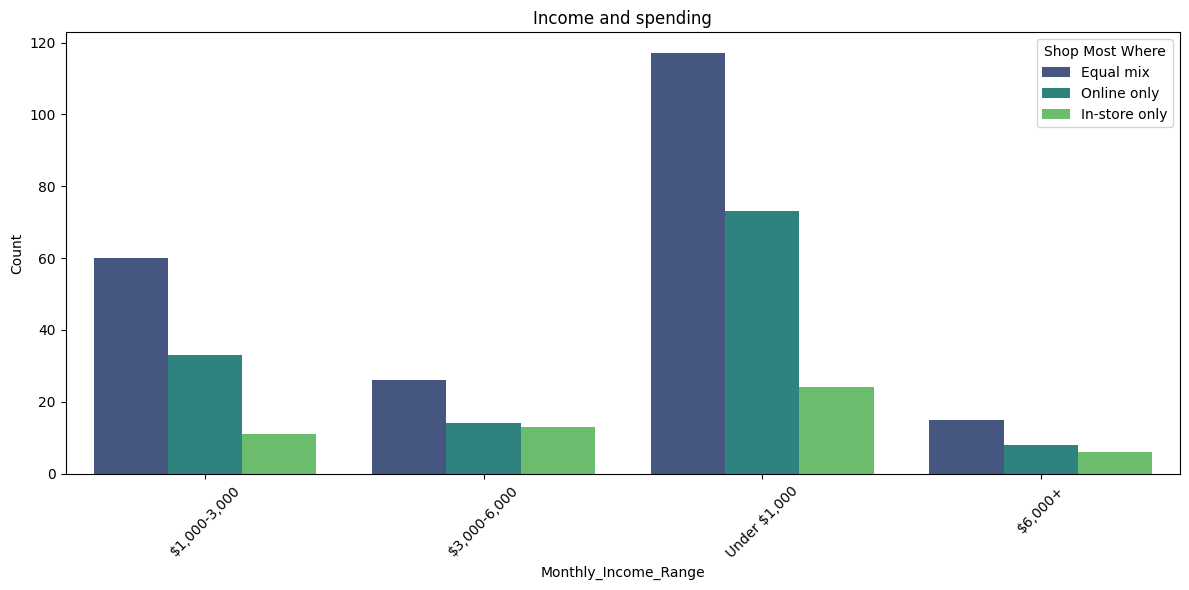

In [76]:
plt.figure(figsize=(12, 6))
sns.countplot(data=X_train, x='Monthly_Income_Range', hue='Shop_Most_Where', palette='viridis')

plt.title("Income and spending")
plt.xlabel("Monthly_Income_Range")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Shop Most Where")
plt.tight_layout()
plt.show()

,Online_Shopping_Satisfaction_Score,Review_Influence_Score
Best_Shopping_Mode,,
Equal / both,7.010989,2.978022
Offline,7.351064,3.085106
Online,7.000000,3.088372


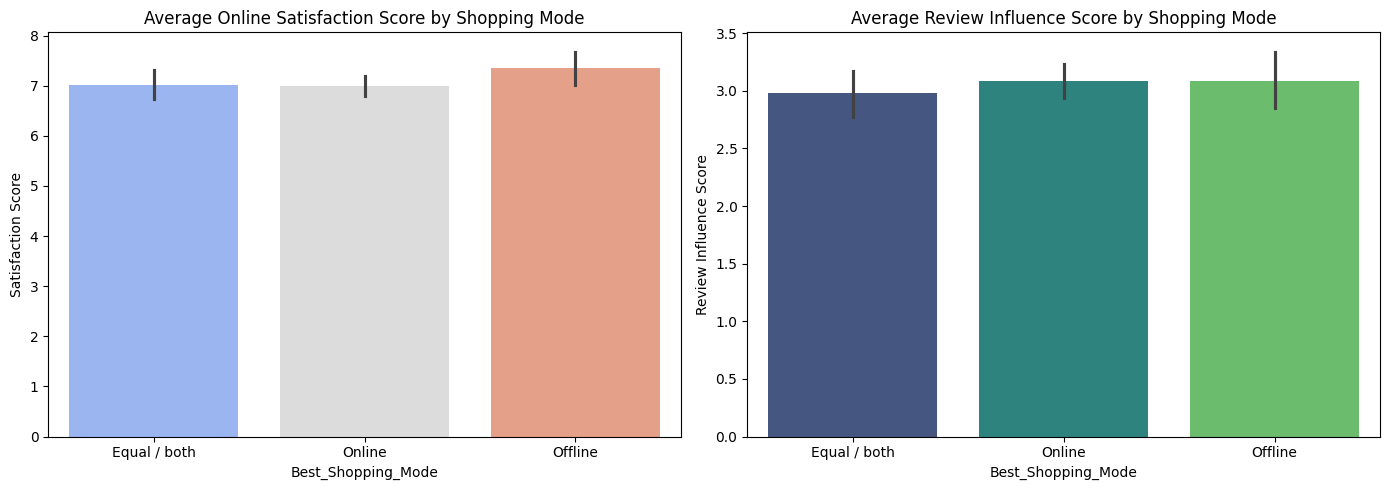

In [79]:
# Combine X_train and the original targets to analyze relationships
temp_df = X_train.copy()
temp_df['Best_Shopping_Mode'] = df_clean.loc[X_train.index, 'Best_Shopping_Mode']

# Group and calculate mean satisfaction and review influence scores
summary = temp_df.groupby('Best_Shopping_Mode')[['Online_Shopping_Satisfaction_Score', 'Review_Influence_Score']].mean()
display(summary)

# Plot the relationships
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(ax=axes[0], data=temp_df, x='Best_Shopping_Mode', y='Online_Shopping_Satisfaction_Score', hue='Best_Shopping_Mode', palette='coolwarm', legend=False)
axes[0].set_title('Average Online Satisfaction Score by Shopping Mode')
axes[0].set_ylabel('Satisfaction Score')

sns.barplot(ax=axes[1], data=temp_df, x='Best_Shopping_Mode', y='Review_Influence_Score', hue='Best_Shopping_Mode', palette='viridis', legend=False)
axes[1].set_title('Average Review Influence Score by Shopping Mode')
axes[1].set_ylabel('Review Influence Score')

plt.tight_layout()
plt.show()

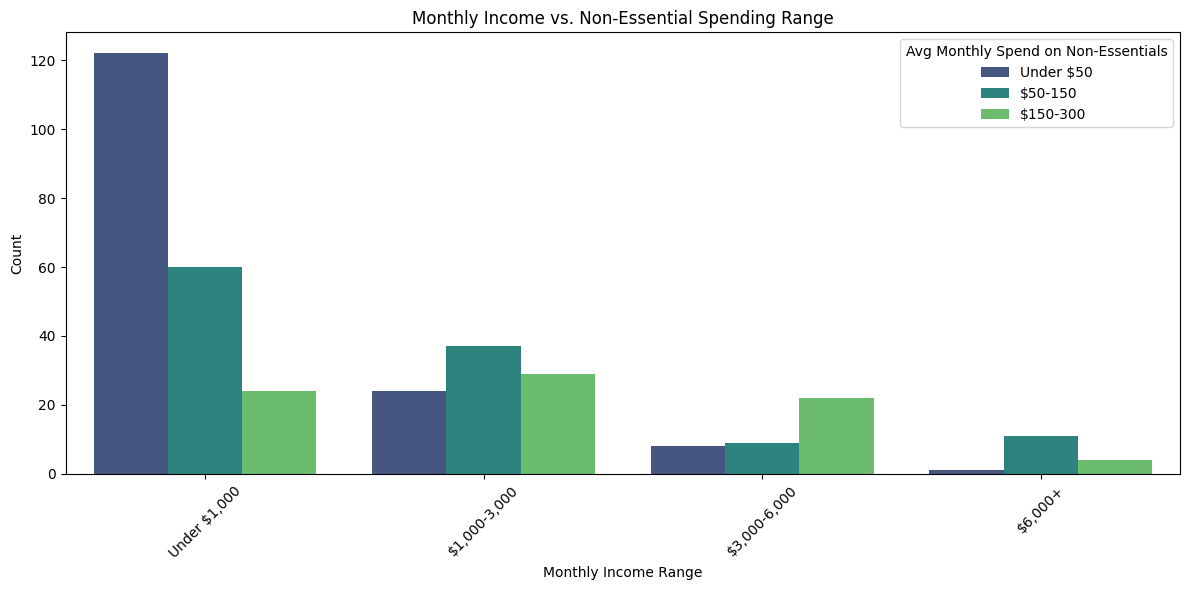

In [80]:
# Define logical order for income and spending ranges for correct plotting
income_order = ['Under $1,000', '$1,000-3,000', '$3,000-6,000', '$6,000+']
spend_order = ['Under $50', '$50-150', '$150-300', '$300+']

# Filter X_train to match only valid ranges if they exist
plt.figure(figsize=(12, 6))
sns.countplot(
    data=X_train,
    x='Monthly_Income_Range',
    hue='Avg_Monthly_Spend_NonEssentials',
    order=[inc for inc in income_order if inc in X_train['Monthly_Income_Range'].unique()],
    hue_order=[sp for sp in spend_order if sp in X_train['Avg_Monthly_Spend_NonEssentials'].unique()],
    palette='viridis'
)

plt.title("Monthly Income vs. Non-Essential Spending Range")
plt.xlabel("Monthly Income Range")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Avg Monthly Spend on Non-Essentials")
plt.tight_layout()
plt.show()

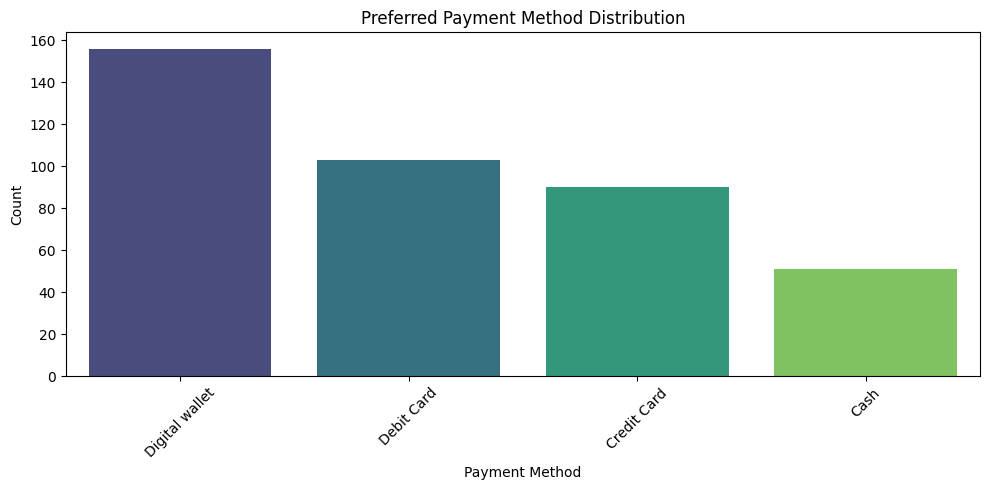

In [83]:
# payment method distribution
plt.figure(figsize=(10, 5))

# Map x to hue and set legend=False to resolve the Seaborn deprecation warning
sns.countplot(
    data=X_train,
    x='Preferred_Payment_Method',
    hue='Preferred_Payment_Method',
    order=X_train['Preferred_Payment_Method'].value_counts().index,
    palette='viridis',
    legend=False
)

plt.title("Preferred Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ANALYTICAL

high income customers prefer more online. income affects the online shoping more.

task 4

In [85]:
# Align test set features with training set features to resolve column mismatch
X_train_final, X_test_final = new_X_train.align(new_X_test, join='left', axis=1, fill_value=0)

clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)
}

for name, model in clf_models.items():
    model.fit(X_train_final, y_train)
    y_pred = model.predict(X_test_final)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f"{name:20s} | Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")

# Detailed Report for Best Model
# print(classification_report(y_test, y_pred))

Logistic Regression  | Accuracy: 0.5300 | F1-Score: 0.5247
Decision Tree        | Accuracy: 0.4800 | F1-Score: 0.4668
Random Forest        | Accuracy: 0.6000 | F1-Score: 0.5099
XGBoost              | Accuracy: 0.5800 | F1-Score: 0.5538


In [88]:
rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

# RandomizedSearchCV is much faster than GridSearchCV!
search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=5,           # Number of random combinations to try (keep small for speed)
    cv=3,               # 3-fold cross validation
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

search.fit(X_train_final, y_train)

best_model = search.best_estimator_
print("Best Parameters:", search.best_params_)
print("Tuned Test Score:", best_model.score(X_test_final, y_test))

Best Parameters: {'n_estimators': 50, 'min_samples_split': 5, 'max_depth': 20}
Tuned Test Score: 0.59


Classification Report for Tuned Random Forest:
              precision    recall  f1-score   support

Equal / both       0.20      0.05      0.07        22
     Offline       0.69      0.38      0.49        24
      Online       0.60      0.91      0.72        54

    accuracy                           0.59       100
   macro avg       0.50      0.44      0.43       100
weighted avg       0.53      0.59      0.52       100



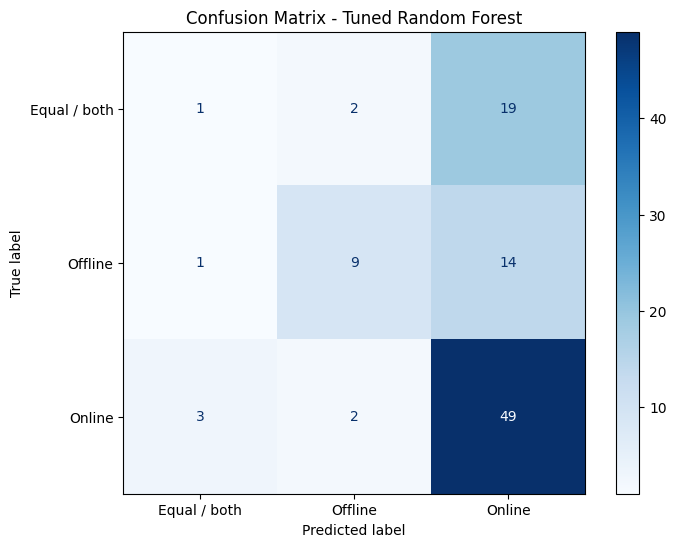

In [91]:
from sklearn.metrics import ConfusionMatrixDisplay

# Calculate predictions for the tuned Random Forest model
y_pred_tuned = best_model.predict(X_test_final)

# 1. Display detailed classification report
print("Classification Report for Tuned Random Forest:")
print(classification_report(y_test, y_pred_tuned, target_names=le.classes_))

# 2. Plot Confusion Matrix
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test_final,
    y_test,
    display_labels=le.classes_,
    cmap='Blues',
    ax=plt.gca()
)
plt.title("Confusion Matrix - Tuned Random Forest")
plt.grid(False)
plt.show()

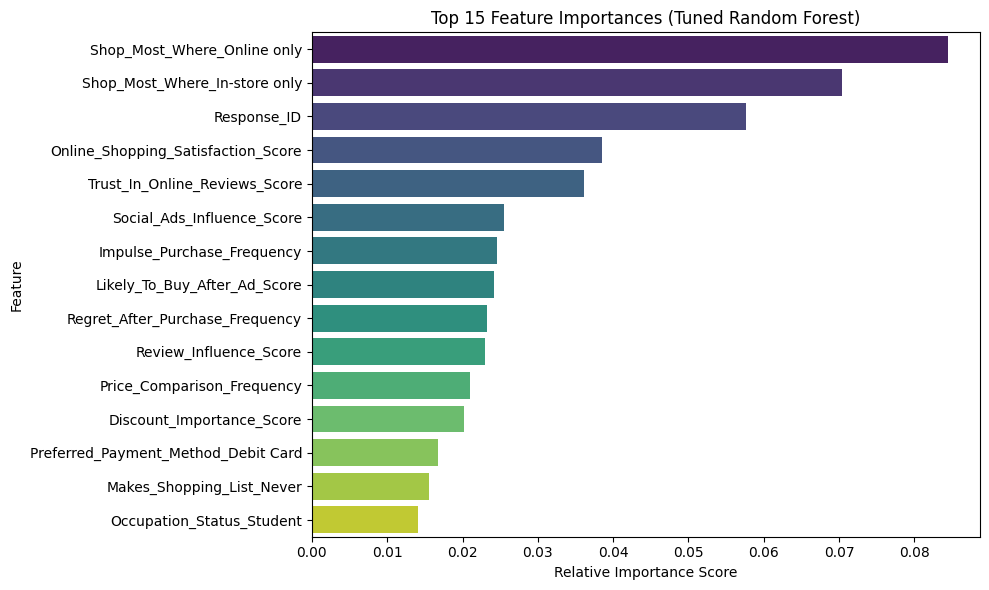

In [92]:
# 3. Extract and Plot Top 15 Feature Importances
importances = best_model.feature_importances_
feature_names = X_train_final.columns

# Create a DataFrame for visualization
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df.head(15),
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title("Top 15 Feature Importances (Tuned Random Forest)")
plt.xlabel("Relative Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [89]:
# --- SAVING USING JOBLIB (Recommended) ---
artifacts = {
    'model': best_model,
    'scaler': scaler,
    'feature_columns': feature_columns
    # 'label_encoder': le  # Include if you encoded target y
}

joblib.dump(artifacts, 'model_artifacts.joblib')
print("Saved successfully as model_artifacts.joblib!")

# Download file from Google Colab to your local PC (for VS Code Flask app)
from google.colab import files
# files.download('model_artifacts.joblib')

Saved successfully as model_artifacts.joblib!


In [90]:
from google.colab import files

# Trigger browser download of the saved model artifacts
files.download('model_artifacts.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

XGBoost performed well. with comparable high score of f1. the model might makes much mistake in class imbalance. causing comparably less scores in predicting, with comparable high score of f1. shopping satisfaction score and online inshop are some of the contributing top features